## Mass calibration and IM window determination

For each precursor, the XICs of the monoisotopic ion and its product ions are extracted. The observed m/z at the apex of each XIC is recorded and the observed m/z of the monoisotopic XIC is used for MS1-level mass calibration. Among all product ion XICs for a given precursor, one is selected as the best MS2-level XIC, and its observed m/z is used for MS2-level mass calibration. 

In [1]:
import numpy as np
import pandas as pd

mass_cali_data = pd.read_csv(r"..\tests\H6_3_S1-D10_1_660_mass_cal.csv")
mass_cali_data.head(6)

,theoretical_mz_ms1,theoretical_mz_ms2,observed_mz_ms1,observed_mz_ms2,mass_delta_ms1,mass_delta_ms2,experimental_rt,query_mz_ms1,query_mz_ms2
0,544.911804,477.241577,544.915466,477.243866,0.003662,0.002289,4.062375,544.916004,477.244687
1,591.286499,540.288879,591.291748,540.292053,0.005249,0.003174,4.689198,591.291106,540.292463
2,573.293457,999.474182,573.298645,999.481995,0.005188,0.007812,4.703402,573.297899,999.480523
3,553.284546,707.880432,553.289490,707.885132,0.004944,0.004700,4.719384,553.288815,707.885164
4,612.941284,862.366272,612.945129,862.374817,0.003845,0.008545,4.738917,612.946099,862.371918
5,542.997742,711.797668,543.002930,711.802246,0.005188,0.004578,4.973305,543.001926,711.802425


In [2]:
from jumpdiaq.calibration import split_into_rt_bins

# sort by RT
mass_cali_data = mass_cali_data.sort_values(by="experimental_rt")

# setup for mass calibration bins
(mass_cal_bins, 
 mass_cal_split, 
 mass_cal_center) = split_into_rt_bins(mass_cali_data['experimental_rt'].to_numpy(), 
                                       max_num_bins=1, # maximum number of bins
                                       min_points_per_bin=500, # minimum number of data points needed for a bin
                                       tolerance=1e-6)

print(mass_cal_bins)
print(mass_cal_split)
print(mass_cal_center)

1
[np.float64(4.0623755), np.float64(41.947803)]
[np.float64(23.00508925)]


In [3]:
from jumpdiaq.calibration import build_mass_cali_model, predicted_mz_parallel, mass_calibration_plot

def mass_calibration(mass_cali_data, level, mass_cal_center, mass_cal_bins):
    assert level in ['ms1', 'ms2']

    theo_col = f'theoretical_mz_{level}'
    delta_col = f'mass_delta_{level}'
    obs_col = f'observed_mz_{level}'
    query_col = f'query_mz_{level}'

    # Step 1: Check mass error before correction
    theo = mass_cali_data[theo_col].to_numpy()
    b_r = mass_cali_data[delta_col].to_numpy() / theo
    mean = np.mean(b_r)
    sd = np.std(b_r)
    print(f"Mean and SD of {level.upper()} mass error before calibration: {np.round(mean * 1e6, 2)} and {np.round(sd * 1e6, 2)} ppm")
    acc_no_cal = np.round(max(abs(mean+3*sd), abs(mean-3*sd)) * 1e6 + 5) / 1e6
    
    # Step 2: Build calibration model
    correction = build_mass_cali_model(
        theoretical_mzs = mass_cali_data[theo_col].to_numpy(),
        delta_mzs = mass_cali_data[delta_col].to_numpy(),
        rts = mass_cali_data['experimental_rt'].to_numpy(),
        RTBinCenter = mass_cal_center,
        nRTBins = mass_cal_bins
    )

    # Step 3: Recalculate query m/z
    query_mz = predicted_mz_parallel(
        correction,
        mass_cali_data[theo_col].to_numpy().reshape(-1, 1),
        mass_cali_data['experimental_rt'].to_numpy(),
        mass_cal_center,
        mass_cal_bins
    ).reshape(-1)
    mass_cali_data[query_col] = query_mz

    # Step 4: Compute mass error
    observed = mass_cali_data[obs_col].to_numpy()
    b_r = (observed - query_mz) / theo
    mean = np.mean(b_r)
    sd = np.std(b_r)
    print(f"Mean and SD of {level.upper()} mass error after calibration: {np.round(mean * 1e6, 2)} and {np.round(sd * 1e6, 2)} ppm")
    acc = np.round(max(abs(mean+3*sd), abs(mean-3*sd)) * 1e6 + 5) / 1e6
    print(f'{level.upper()} mass accuracy set to {acc*1e6} ppm')

    if acc_no_cal < acc:
        print(f"No {level.upper()} mass correction required")
        print(f'{level.upper()} mass accuracy reset to {acc_no_cal*1e6} ppm')
    
    return mass_cali_data

Mean and SD of MS1 mass error before calibration: 8.39 and 2.46 ppm
Mean and SD of MS1 mass error after calibration: -0.0 and 2.37 ppm
MS1 mass accuracy set to 12.0 ppm
Mean and SD of MS2 mass error before calibration: 6.51 and 1.9 ppm
Mean and SD of MS2 mass error after calibration: 0.0 and 1.9 ppm
MS2 mass accuracy set to 11.0 ppm


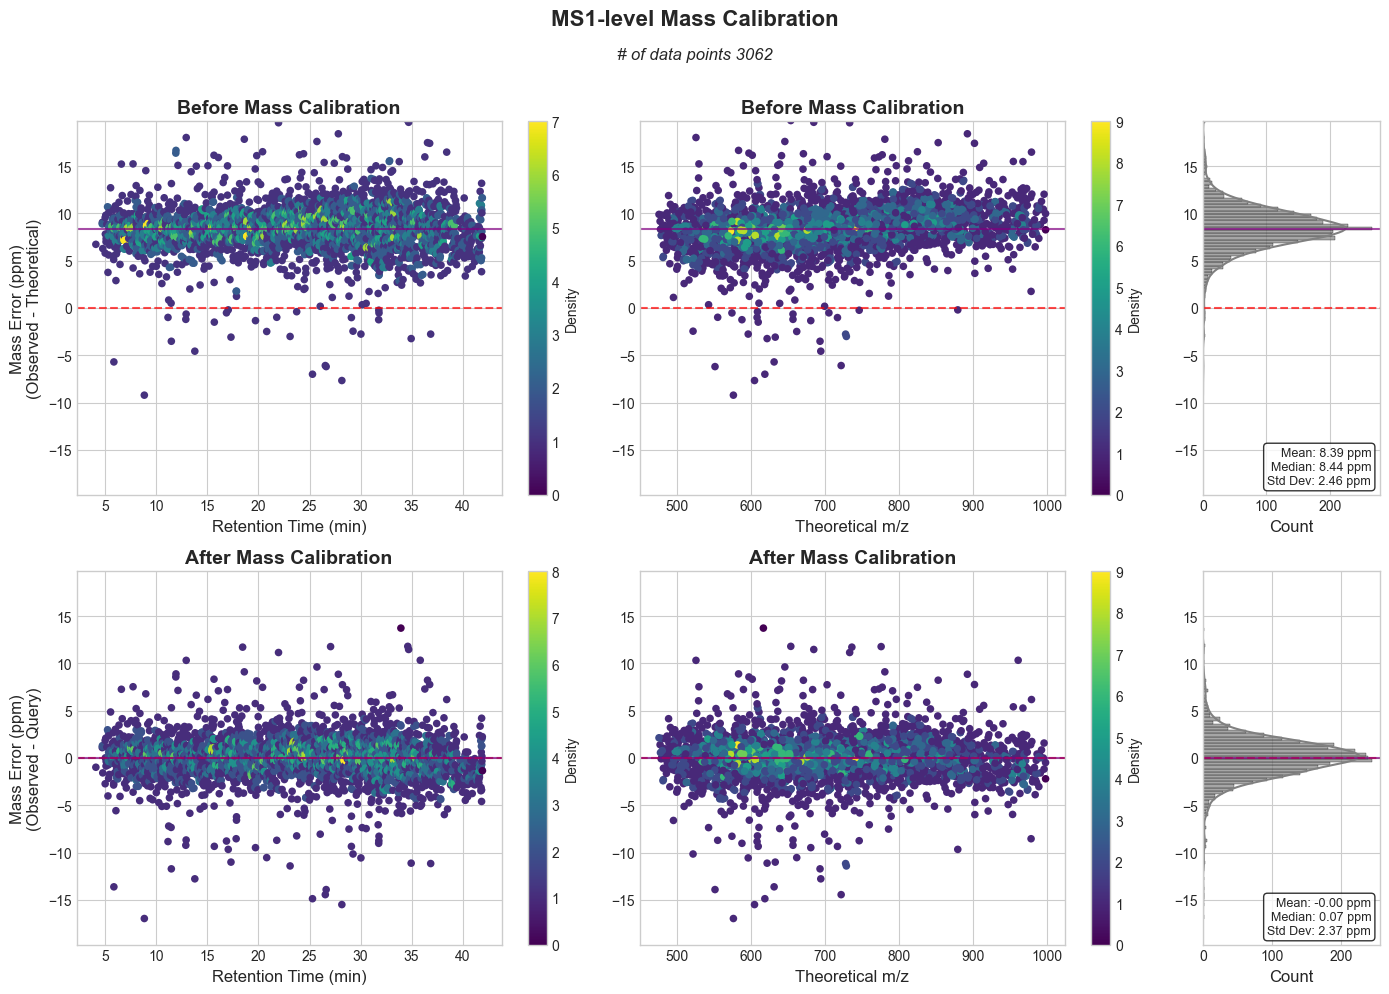

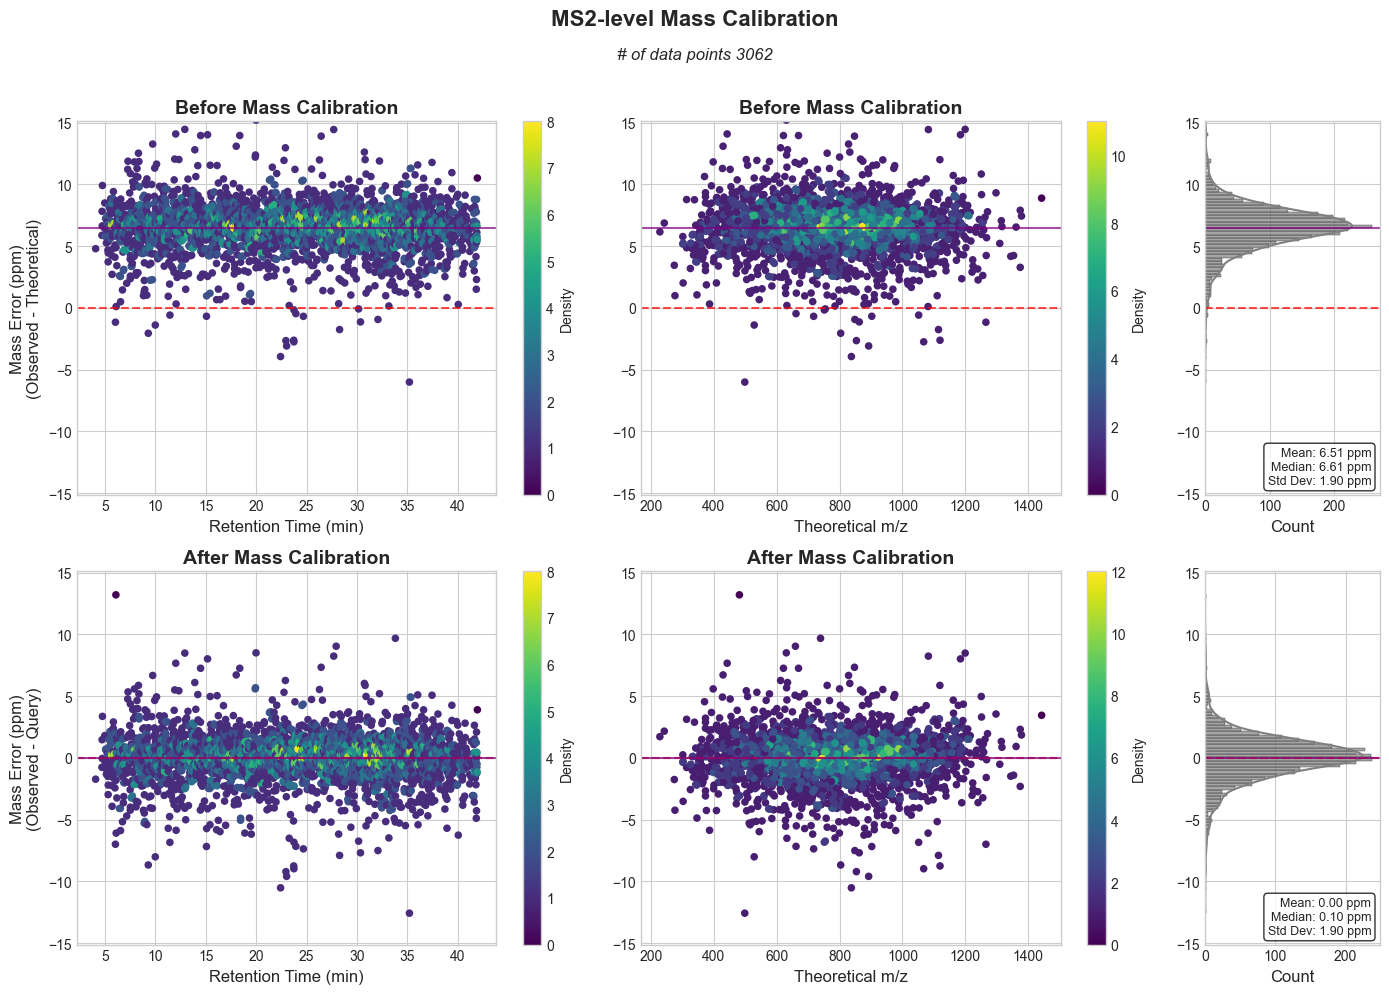

In [4]:
mass_cali_data = mass_calibration(mass_cali_data, 'ms1', mass_cal_center, mass_cal_bins)
mass_cali_data = mass_calibration(mass_cali_data, 'ms2', mass_cal_center, mass_cal_bins)

mass_calibration_plot(mass_cali_data, 'ms1', run_name='', save_plot=False)
mass_calibration_plot(mass_cali_data, 'ms2', run_name='', save_plot=False)

### Determine IM window


In [5]:
im_cali_data = pd.read_csv(r"..\tests\H6_3_S1-D10_1_660_im_error.csv") 
im_cali_data = im_cali_data.sort_values(by="query_im")
print(f"{len(im_cali_data)} IM values are used for IM window determination") 
im_cali_data.head(6)

3064 IM values are used for IM window determination


,theoretical_mz,query_im,im_delta
0,568.532288,0.851544,-0.001522
1,520.243896,0.852500,-0.005904
2,494.893127,0.852500,-0.007856
3,550.961853,0.852500,0.006337
4,500.794922,0.852500,-0.006281
5,478.779816,0.852654,-0.002923


Mean and SD of ion mobility error: -0.0006 and 0.00229


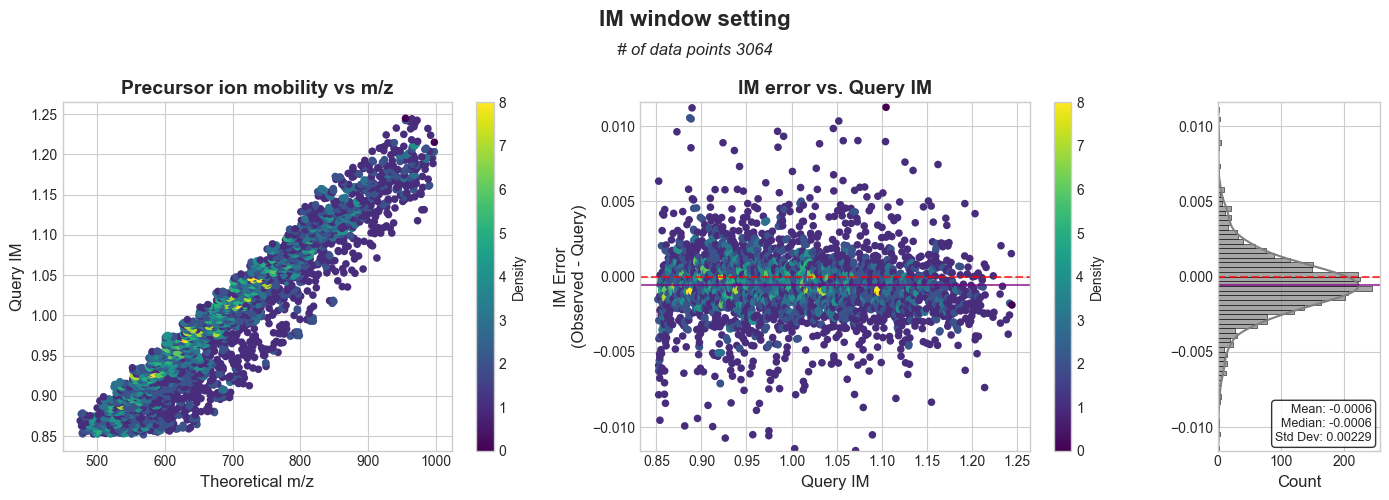

In [6]:
from jumpdiaq.calibration import im_error_plot

# calibration       
mean = im_cali_data['im_delta'].mean()
sd = im_cali_data['im_delta'].std()
print(f"Mean and SD of ion mobility error: {np.round(mean, 4)} and {np.round(sd, 5)}")
im_boundary = max(abs(mean+3*sd), abs(mean-3*sd)) * 1.25
IM_window = np.round(im_boundary, 3)

im_error_plot(im_cali_data, run_name="", save_plot=False)